In [1]:
import pandas as pd

train = pd.read_csv("train.csv")
print(train.shape)
train.head()

(18, 7)


,No,material,feedrate,clamp_pressure,tool_condition,machining_finalized,passed_visual_inspection
0,1,wax,6,4.0,unworn,yes,yes
1,2,wax,20,4.0,unworn,yes,yes
2,3,wax,6,3.0,unworn,yes,yes
3,4,wax,6,2.5,unworn,no,NaN
4,5,wax,20,3.0,unworn,no,NaN


In [2]:
exp1 = pd.read_csv("experiment_01.csv")
print(exp1.shape)
exp1.head()

(1055, 48)


,X1_ActualPosition,X1_ActualVelocity,X1_ActualAcceleration,X1_CommandPosition,X1_CommandVelocity,X1_CommandAcceleration,X1_CurrentFeedback,X1_DCBusVoltage,X1_OutputCurrent,X1_OutputVoltage,...,S1_CurrentFeedback,S1_DCBusVoltage,S1_OutputCurrent,S1_OutputVoltage,S1_OutputPower,S1_SystemInertia,M1_CURRENT_PROGRAM_NUMBER,M1_sequence_number,M1_CURRENT_FEEDRATE,Machining_Process
0,198.0,0.0,0.00,198.0,0.0,0.000000,0.18,0.0207,329.0,2.77,...,0.524,2.740000e-19,329.0,0.0,6.960000e-07,12.0,1.0,0.0,50.0,Starting
1,198.0,-10.8,-350.00,198.0,-13.6,-358.000000,-10.90,0.1860,328.0,23.30,...,-0.288,2.740000e-19,328.0,0.0,-5.270000e-07,12.0,1.0,4.0,50.0,Prep
2,196.0,-17.8,-6.25,196.0,-17.9,-0.000095,-8.59,0.1400,328.0,30.60,...,0.524,2.740000e-19,328.0,0.0,9.100000e-07,12.0,1.0,7.0,50.0,Prep
3,194.0,-18.0,0.00,194.0,-17.9,-0.000095,-6.11,0.1300,327.0,30.30,...,-0.180,2.740000e-19,328.0,0.0,1.070000e-06,12.0,1.0,7.0,50.0,Prep
4,193.0,-17.9,-18.80,192.0,-17.9,0.000095,-5.70,0.1140,328.0,30.50,...,0.226,2.740000e-19,328.0,0.0,1.960000e-06,12.0,1.0,7.0,50.0,Prep


In [3]:
print(train.columns)

Index(['No', 'material', 'feedrate', 'clamp_pressure', 'tool_condition',
       'machining_finalized', 'passed_visual_inspection'],
      dtype='object')


In [4]:
print(train.columns)
train

Index(['No', 'material', 'feedrate', 'clamp_pressure', 'tool_condition',
       'machining_finalized', 'passed_visual_inspection'],
      dtype='object')


,No,material,feedrate,clamp_pressure,tool_condition,machining_finalized,passed_visual_inspection
0,1,wax,6,4.0,unworn,yes,yes
1,2,wax,20,4.0,unworn,yes,yes
2,3,wax,6,3.0,unworn,yes,yes
3,4,wax,6,2.5,unworn,no,NaN
4,5,wax,20,3.0,unworn,no,NaN
5,6,wax,6,4.0,worn,yes,no
6,7,wax,20,4.0,worn,no,NaN
7,8,wax,20,4.0,worn,yes,no
8,9,wax,15,4.0,worn,yes,no
9,10,wax,12,4.0,worn,yes,no


In [5]:
print(train["tool_condition"].value_counts())

tool_condition
worn      10
unworn     8
Name: count, dtype: int64


In [6]:
exp1.columns

Index(['X1_ActualPosition', 'X1_ActualVelocity', 'X1_ActualAcceleration',
       'X1_CommandPosition', 'X1_CommandVelocity', 'X1_CommandAcceleration',
       'X1_CurrentFeedback', 'X1_DCBusVoltage', 'X1_OutputCurrent',
       'X1_OutputVoltage', 'X1_OutputPower', 'Y1_ActualPosition',
       'Y1_ActualVelocity', 'Y1_ActualAcceleration', 'Y1_CommandPosition',
       'Y1_CommandVelocity', 'Y1_CommandAcceleration', 'Y1_CurrentFeedback',
       'Y1_DCBusVoltage', 'Y1_OutputCurrent', 'Y1_OutputVoltage',
       'Y1_OutputPower', 'Z1_ActualPosition', 'Z1_ActualVelocity',
       'Z1_ActualAcceleration', 'Z1_CommandPosition', 'Z1_CommandVelocity',
       'Z1_CommandAcceleration', 'Z1_CurrentFeedback', 'Z1_DCBusVoltage',
       'Z1_OutputCurrent', 'Z1_OutputVoltage', 'S1_ActualPosition',
       'S1_ActualVelocity', 'S1_ActualAcceleration', 'S1_CommandPosition',
       'S1_CommandVelocity', 'S1_CommandAcceleration', 'S1_CurrentFeedback',
       'S1_DCBusVoltage', 'S1_OutputCurrent', 'S1_OutputVolt

In [7]:
print(exp1.describe())
print(exp1.isna().sum())

       X1_ActualPosition  X1_ActualVelocity  X1_ActualAcceleration  \
count        1055.000000        1055.000000            1055.000000   
mean          151.998104          -0.514919               4.252891   
std             8.315984           5.875864             103.299534   
min           141.000000         -18.100000           -1090.000000   
25%           145.000000          -5.690000             -37.500000   
50%           151.000000          -0.050000               0.000000   
75%           159.000000           4.140000              37.500000   
max           198.000000          44.900000            1030.000000   

       X1_CommandPosition  X1_CommandVelocity  X1_CommandAcceleration  \
count         1055.000000         1055.000000             1055.000000   
mean           151.999052           -0.516069                0.075188   
std              8.309193            5.871274               81.316778   
min            141.000000          -17.900000             -922.000000   
25% 

My hypotheses

A worn tool needs more cutting force, so I expect the spindle current to be higher for worn tools.
A worn tool cuts less smoothly, so I expect more vibration, which means the sensor values should vary more.
I think feed rate and clamp pressure may also affect how quickly a tool wears.

In [8]:
import pandas as pd

train = pd.read_csv("train.csv")

frames = []
for i in range(1, len(train) + 1):
    name = f"experiment_{i:02d}.csv"      # experiment_01.csv, experiment_02.csv ...
    df = pd.read_csv(name)
    df["experiment"] = i                  # remember which experiment each row came from
    frames.append(df)

sensors = pd.concat(frames, ignore_index=True)
print(sensors.shape)

(25286, 49)


In [9]:
data = sensors.merge(train[["No", "tool_condition"]],
                     left_on="experiment", right_on="No")
print(data.shape)
data[["experiment", "tool_condition"]].drop_duplicates()

(25286, 51)


,experiment,tool_condition
0,1,unworn
1055,2,unworn
2723,3,unworn
4244,4,unworn
4776,5,unworn
5238,6,worn
6534,7,worn
7099,8,worn
7704,9,worn
8444,10,worn


In [10]:
print(data.isna().sum().sum())      # total missing values
print(data.duplicated().sum())      # duplicate rows

0
331


In [11]:
print(data.shape)

dups = data[data.duplicated(keep=False)]
print(dups.groupby("experiment").size())
dups.head(10)

(25286, 51)
experiment
2     211
5     112
11    106
12      4
dtype: int64


,X1_ActualPosition,X1_ActualVelocity,X1_ActualAcceleration,X1_CommandPosition,X1_CommandVelocity,X1_CommandAcceleration,X1_CurrentFeedback,X1_DCBusVoltage,X1_OutputCurrent,X1_OutputVoltage,...,S1_OutputVoltage,S1_OutputPower,S1_SystemInertia,M1_CURRENT_PROGRAM_NUMBER,M1_sequence_number,M1_CURRENT_FEEDRATE,Machining_Process,experiment,No,tool_condition
1076,198.0,0.0,0.0,198.0,0.0,0.0,-0.6380,2.790000e-19,328.0,0.0,...,0.0,-0.000014,12.0,0.0,0.0,50.0,Prep,2,2,unworn
1077,198.0,0.0,0.0,198.0,0.0,0.0,-0.6380,2.790000e-19,328.0,0.0,...,0.0,-0.000014,12.0,0.0,0.0,50.0,Prep,2,2,unworn
1104,198.0,0.0,0.0,198.0,0.0,0.0,-0.0925,2.790000e-19,328.0,0.0,...,0.0,0.000021,12.0,0.0,0.0,50.0,Prep,2,2,unworn
1105,198.0,0.0,0.0,198.0,0.0,0.0,-0.0925,2.790000e-19,328.0,0.0,...,0.0,0.000021,12.0,0.0,0.0,50.0,Prep,2,2,unworn
1128,198.0,0.0,0.0,198.0,0.0,0.0,1.0300,2.790000e-19,328.0,0.0,...,0.0,0.000000,12.0,0.0,0.0,50.0,Prep,2,2,unworn
1129,198.0,0.0,0.0,198.0,0.0,0.0,1.0300,2.790000e-19,328.0,0.0,...,0.0,0.000000,12.0,0.0,0.0,50.0,Prep,2,2,unworn
1198,198.0,0.0,0.0,198.0,0.0,0.0,-0.6380,2.790000e-19,328.0,0.0,...,0.0,0.000008,12.0,0.0,0.0,50.0,Prep,2,2,unworn
1199,198.0,0.0,0.0,198.0,0.0,0.0,-0.6380,2.790000e-19,328.0,0.0,...,0.0,0.000008,12.0,0.0,0.0,50.0,Prep,2,2,unworn
1226,198.0,0.0,0.0,198.0,0.0,0.0,-0.1470,2.790000e-19,328.0,0.0,...,0.0,0.000007,12.0,0.0,0.0,50.0,Prep,2,2,unworn
1227,198.0,0.0,0.0,198.0,0.0,0.0,-0.1470,2.790000e-19,328.0,0.0,...,0.0,0.000007,12.0,0.0,0.0,50.0,Prep,2,2,unworn


In [12]:
print(data.columns)

Index(['X1_ActualPosition', 'X1_ActualVelocity', 'X1_ActualAcceleration',
       'X1_CommandPosition', 'X1_CommandVelocity', 'X1_CommandAcceleration',
       'X1_CurrentFeedback', 'X1_DCBusVoltage', 'X1_OutputCurrent',
       'X1_OutputVoltage', 'X1_OutputPower', 'Y1_ActualPosition',
       'Y1_ActualVelocity', 'Y1_ActualAcceleration', 'Y1_CommandPosition',
       'Y1_CommandVelocity', 'Y1_CommandAcceleration', 'Y1_CurrentFeedback',
       'Y1_DCBusVoltage', 'Y1_OutputCurrent', 'Y1_OutputVoltage',
       'Y1_OutputPower', 'Z1_ActualPosition', 'Z1_ActualVelocity',
       'Z1_ActualAcceleration', 'Z1_CommandPosition', 'Z1_CommandVelocity',
       'Z1_CommandAcceleration', 'Z1_CurrentFeedback', 'Z1_DCBusVoltage',
       'Z1_OutputCurrent', 'Z1_OutputVoltage', 'S1_ActualPosition',
       'S1_ActualVelocity', 'S1_ActualAcceleration', 'S1_CommandPosition',
       'S1_CommandVelocity', 'S1_CommandAcceleration', 'S1_CurrentFeedback',
       'S1_DCBusVoltage', 'S1_OutputCurrent', 'S1_OutputVolt

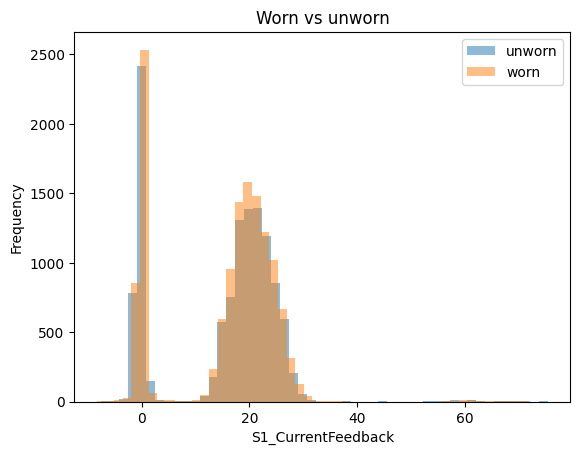

In [13]:
import matplotlib.pyplot as plt

col = "S1_CurrentFeedback"      # replace with your spindle current column

data.groupby("tool_condition")[col].plot(kind="hist", bins=50, alpha=0.5, legend=True)
plt.xlabel(col)
plt.title("Worn vs unworn")
plt.show()

In [14]:
print(data.groupby("tool_condition")[col].mean())


tool_condition
unworn    15.004511
worn      15.459456
Name: S1_CurrentFeedback, dtype: float64


In [15]:
cutting = data[data[col] > 5]
print(cutting.groupby("tool_condition")[col].mean())

tool_condition
unworn    20.981721
worn      20.953644
Name: S1_CurrentFeedback, dtype: float64


In [16]:
import numpy as np

col = "S1_CurrentFeedback"
cutting = data[data[col] > 5].copy()

print(data.shape, "->", cutting.shape)
print(cutting["experiment"].nunique())

(25286, 51) -> (18402, 51)
18


In [17]:
cutting["window"] = cutting.groupby("experiment")["experiment"].transform(
    lambda s: pd.cut(np.arange(len(s)), 20, labels=False)
)
print(cutting[["experiment", "window"]].drop_duplicates().shape)

(360, 2)


In [18]:
drop = ["experiment", "No", "tool_condition", "window",
        "Machining_Process", "M1_CURRENT_PROGRAM_NUMBER", "M1_sequence_number"]

sensor_cols = [c for c in cutting.select_dtypes(include="number").columns
               if c not in drop]
print(len(sensor_cols))
print(sensor_cols)

45
['X1_ActualPosition', 'X1_ActualVelocity', 'X1_ActualAcceleration', 'X1_CommandPosition', 'X1_CommandVelocity', 'X1_CommandAcceleration', 'X1_CurrentFeedback', 'X1_DCBusVoltage', 'X1_OutputCurrent', 'X1_OutputVoltage', 'X1_OutputPower', 'Y1_ActualPosition', 'Y1_ActualVelocity', 'Y1_ActualAcceleration', 'Y1_CommandPosition', 'Y1_CommandVelocity', 'Y1_CommandAcceleration', 'Y1_CurrentFeedback', 'Y1_DCBusVoltage', 'Y1_OutputCurrent', 'Y1_OutputVoltage', 'Y1_OutputPower', 'Z1_ActualPosition', 'Z1_ActualVelocity', 'Z1_ActualAcceleration', 'Z1_CommandPosition', 'Z1_CommandVelocity', 'Z1_CommandAcceleration', 'Z1_CurrentFeedback', 'Z1_DCBusVoltage', 'Z1_OutputCurrent', 'Z1_OutputVoltage', 'S1_ActualPosition', 'S1_ActualVelocity', 'S1_ActualAcceleration', 'S1_CommandPosition', 'S1_CommandVelocity', 'S1_CommandAcceleration', 'S1_CurrentFeedback', 'S1_DCBusVoltage', 'S1_OutputCurrent', 'S1_OutputVoltage', 'S1_OutputPower', 'S1_SystemInertia', 'M1_CURRENT_FEEDRATE']


In [19]:
def rms(x):
    return np.sqrt(np.mean(x ** 2))

features = cutting.groupby(["experiment", "window"])[sensor_cols].agg(
    ["mean", "max", "std", rms]
)

# flatten the two-level column names, e.g. S1_CurrentFeedback_mean
features.columns = ["_".join(c) for c in features.columns]
features = features.reset_index()

In [20]:
labels = train[["No", "tool_condition"]].rename(columns={"No": "experiment"})
features = features.merge(labels, on="experiment")

features = features.fillna(0)   # safety net for any empty std values

print(features.shape)
print(features["tool_condition"].value_counts())
features.head()

(360, 183)
tool_condition
worn      200
unworn    160
Name: count, dtype: int64


,experiment,window,X1_ActualPosition_mean,X1_ActualPosition_max,X1_ActualPosition_std,X1_ActualPosition_rms,X1_ActualVelocity_mean,X1_ActualVelocity_max,X1_ActualVelocity_std,X1_ActualVelocity_rms,...,S1_OutputPower_rms,S1_SystemInertia_mean,S1_SystemInertia_max,S1_SystemInertia_std,S1_SystemInertia_rms,M1_CURRENT_FEEDRATE_mean,M1_CURRENT_FEEDRATE_max,M1_CURRENT_FEEDRATE_std,M1_CURRENT_FEEDRATE_rms,tool_condition
0,1,0,147.269231,156.0,4.111750,147.325516,1.036346,6.30,5.010361,5.069021,...,0.193649,12.0,12.0,0.0,12.0,6.846154,50.0,6.101702,9.131518,unworn
1,1,1,154.823529,159.0,5.034703,154.903765,-2.534118,5.88,3.747037,4.492965,...,0.177207,12.0,12.0,0.0,12.0,6.000000,6.0,0.000000,6.000000,unworn
2,1,2,144.901961,156.0,4.809386,144.980188,2.516078,6.10,3.405538,4.207248,...,0.178497,12.0,12.0,0.0,12.0,6.000000,6.0,0.000000,6.000000,unworn
3,1,3,156.078431,162.0,5.279557,156.165950,-2.089216,6.18,4.508766,4.929014,...,0.177257,12.0,12.0,0.0,12.0,6.000000,6.0,0.000000,6.000000,unworn
4,1,4,151.921569,162.0,6.852279,152.072996,3.390686,6.20,2.889610,4.436539,...,0.175700,12.0,12.0,0.0,12.0,6.000000,6.0,0.000000,6.000000,unworn


In [21]:
print(features.shape)

(360, 183)


In [22]:
print(features["tool_condition"].value_counts())

tool_condition
worn      200
unworn    160
Name: count, dtype: int64


In [23]:
import numpy as np

exp_labels = features.groupby("experiment")["tool_condition"].first()
unworn_exps = exp_labels[exp_labels == "unworn"].index.tolist()
worn_exps = exp_labels[exp_labels == "worn"].index.tolist()

rng = np.random.RandomState(42)    # fixed number, so you get the same split every time
test_exps = list(rng.choice(unworn_exps, 1, replace=False)) + \
            list(rng.choice(worn_exps, 4, replace=False))
test_exps = [int(e) for e in test_exps]

print("Test experiments:", test_exps)

Test experiments: [2, 6, 7, 13, 9]


Why did we remove idle rows and group into windows?

Write this in your own words. These are the points to include:

Idle rows: When the machine isn’t cutting, the sensors read about the same for every tool. Those rows say nothing about wear, and they hid the difference between worn and unworn in your histogram.
Windows: A single row is one noisy moment. A summary of a chunk of time (mean, max, std, RMS) shows the pattern, such as higher load or more variation, which is what wear changes.
Windows also give more rows: With only 18 experiments, the model would have 18 examples. Twenty windows per experiment gives about 360, enough to train and test models.


In [24]:
train_df = features[~features["experiment"].isin(test_exps)]
test_df  = features[features["experiment"].isin(test_exps)]

drop_cols = ["experiment", "window", "tool_condition"]

X_train = train_df.drop(columns=drop_cols)
X_test  = test_df.drop(columns=drop_cols)

# Turn the text labels into numbers: 1 = worn, 0 = unworn
y_train = (train_df["tool_condition"] == "worn").astype(int)
y_test  = (test_df["tool_condition"] == "worn").astype(int)

print(X_train.shape, X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(260, 180) (100, 180)
tool_condition
0    140
1    120
Name: count, dtype: int64
tool_condition
1    80
0    20
Name: count, dtype: int64


In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn the scale from TRAIN only
X_test_scaled  = scaler.transform(X_test)        # apply the same scale to TEST

print(X_train_scaled.shape, X_test_scaled.shape)


(260, 180) (100, 180)


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=42),
    "SVM": SVC(class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

rows = []
matrices = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)          # learn from the training data
    pred = model.predict(X_test_scaled)         # predict on unseen test data
    matrices[name] = confusion_matrix(y_test, pred)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (worn)": precision_score(y_test, pred, zero_division=0),
        "Recall (worn)": recall_score(y_test, pred),
        "Recall (unworn)": recall_score(y_test, pred, pos_label=0),
        "F1 (worn)": f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).round(3)
results

,Model,Accuracy,Precision (worn),Recall (worn),Recall (unworn),F1 (worn)
0,Logistic Regression,0.44,0.688,0.550,0.00,0.611
1,KNN,0.46,0.697,0.575,0.00,0.630
2,Decision Tree,0.79,0.904,0.825,0.65,0.863
3,Random Forest,0.45,0.692,0.562,0.00,0.621
4,SVM,0.45,0.692,0.562,0.00,0.621
5,Gradient Boosting,0.53,0.811,0.538,0.50,0.647


In [28]:
for name, m in matrices.items():
    print(name)
    print(m)
    print()

Logistic Regression
[[ 0 20]
 [36 44]]

KNN
[[ 0 20]
 [34 46]]

Decision Tree
[[13  7]
 [14 66]]

Random Forest
[[ 0 20]
 [35 45]]

SVM
[[ 0 20]
 [35 45]]

Gradient Boosting
[[10 10]
 [37 43]]



In [29]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import accuracy_score, recall_score, balanced_accuracy_score
import pandas as pd

X_all = features.drop(columns=["experiment", "window", "tool_condition"])
y_all = (features["tool_condition"] == "worn").astype(int)
groups = features["experiment"]

feature_sets = {
    "All features": list(X_all.columns),
    "Without position": [c for c in X_all.columns if "Position" not in c],
    "Current/Power/Voltage only": [c for c in X_all.columns
                                   if any(k in c for k in ["Current", "Power", "Voltage"])],
}

for name, cols in feature_sets.items():
    print(name, "->", len(cols), "columns")

All features -> 180 columns
Without position -> 148 columns
Current/Power/Voltage only -> 76 columns


In [30]:
print(list(X_all.columns)[:40])

['X1_ActualPosition_mean', 'X1_ActualPosition_max', 'X1_ActualPosition_std', 'X1_ActualPosition_rms', 'X1_ActualVelocity_mean', 'X1_ActualVelocity_max', 'X1_ActualVelocity_std', 'X1_ActualVelocity_rms', 'X1_ActualAcceleration_mean', 'X1_ActualAcceleration_max', 'X1_ActualAcceleration_std', 'X1_ActualAcceleration_rms', 'X1_CommandPosition_mean', 'X1_CommandPosition_max', 'X1_CommandPosition_std', 'X1_CommandPosition_rms', 'X1_CommandVelocity_mean', 'X1_CommandVelocity_max', 'X1_CommandVelocity_std', 'X1_CommandVelocity_rms', 'X1_CommandAcceleration_mean', 'X1_CommandAcceleration_max', 'X1_CommandAcceleration_std', 'X1_CommandAcceleration_rms', 'X1_CurrentFeedback_mean', 'X1_CurrentFeedback_max', 'X1_CurrentFeedback_std', 'X1_CurrentFeedback_rms', 'X1_DCBusVoltage_mean', 'X1_DCBusVoltage_max', 'X1_DCBusVoltage_std', 'X1_DCBusVoltage_rms', 'X1_OutputCurrent_mean', 'X1_OutputCurrent_max', 'X1_OutputCurrent_std', 'X1_OutputCurrent_rms', 'X1_OutputVoltage_mean', 'X1_OutputVoltage_max', 'X1_O

In [31]:
logo = LeaveOneGroupOut()
rows = []

for set_name, cols in feature_sets.items():
    for model_name, model in models.items():
        pipe = make_pipeline(StandardScaler(), model)
        pred = cross_val_predict(pipe, X_all[cols], y_all, groups=groups, cv=logo)
        rows.append({
            "Feature set": set_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_all, pred),
            "Recall (worn)": recall_score(y_all, pred),
            "Recall (unworn)": recall_score(y_all, pred, pos_label=0),
            "Balanced accuracy": balanced_accuracy_score(y_all, pred),
        })

cv_results = pd.DataFrame(rows).round(3)
cv_results.sort_values("Balanced accuracy", ascending=False)

,Feature set,Model,Accuracy,Recall (worn),Recall (unworn),Balanced accuracy
2,All features,Decision Tree,0.672,0.760,0.562,0.661
5,All features,Gradient Boosting,0.631,0.730,0.506,0.618
3,All features,Random Forest,0.572,0.675,0.444,0.559
15,Current/Power/Voltage only,Random Forest,0.550,0.590,0.500,0.545
11,Without position,Gradient Boosting,0.539,0.590,0.475,0.532
17,Current/Power/Voltage only,Gradient Boosting,0.533,0.615,0.431,0.523
6,Without position,Logistic Regression,0.531,0.590,0.456,0.523
0,All features,Logistic Regression,0.525,0.590,0.444,0.517
9,Without position,Random Forest,0.514,0.570,0.444,0.507
13,Current/Power/Voltage only,KNN,0.517,0.625,0.381,0.503


In [32]:
cv_results.sort_values("Balanced accuracy", ascending=False).head(10)

,Feature set,Model,Accuracy,Recall (worn),Recall (unworn),Balanced accuracy
2,All features,Decision Tree,0.672,0.760,0.562,0.661
5,All features,Gradient Boosting,0.631,0.730,0.506,0.618
3,All features,Random Forest,0.572,0.675,0.444,0.559
15,Current/Power/Voltage only,Random Forest,0.550,0.590,0.500,0.545
11,Without position,Gradient Boosting,0.539,0.590,0.475,0.532
17,Current/Power/Voltage only,Gradient Boosting,0.533,0.615,0.431,0.523
6,Without position,Logistic Regression,0.531,0.590,0.456,0.523
0,All features,Logistic Regression,0.525,0.590,0.444,0.517
9,Without position,Random Forest,0.514,0.570,0.444,0.507
13,Current/Power/Voltage only,KNN,0.517,0.625,0.381,0.503


In [33]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
import pandas as pd

dt = DecisionTreeClassifier(class_weight="balanced", random_state=42).fit(X_all, y_all)
gb = GradientBoostingClassifier(random_state=42).fit(X_all, y_all)

imp = pd.DataFrame({
    "Feature": X_all.columns,
    "Decision Tree": dt.feature_importances_,
    "Gradient Boosting": gb.feature_importances_,
})

print("Top 10, Decision Tree:")
print(imp.sort_values("Decision Tree", ascending=False).head(10)[["Feature", "Decision Tree"]].round(3).to_string(index=False))
print()
print("Top 10, Gradient Boosting:")
print(imp.sort_values("Gradient Boosting", ascending=False).head(10)[["Feature", "Gradient Boosting"]].round(3).to_string(index=False))

Top 10, Decision Tree:
                    Feature  Decision Tree
      Z1_ActualPosition_max          0.356
      Y1_OutputCurrent_mean          0.164
     Z1_CommandPosition_max          0.108
       Y1_OutputCurrent_rms          0.050
       S1_OutputCurrent_std          0.040
       S1_OutputVoltage_rms          0.036
  Y1_ActualAcceleration_max          0.034
X1_CommandAcceleration_mean          0.032
       S1_OutputVoltage_std          0.028
  X1_ActualAcceleration_std          0.028

Top 10, Gradient Boosting:
                  Feature  Gradient Boosting
   Z1_CommandPosition_max              0.305
    Z1_ActualPosition_max              0.221
    Y1_OutputCurrent_mean              0.077
     Y1_OutputCurrent_rms              0.057
S1_ActualAcceleration_rms              0.030
Y1_ActualAcceleration_max              0.029
S1_ActualAcceleration_std              0.018
X1_ActualAcceleration_std              0.017
      S1_OutputPower_mean              0.014
   S1_ActualPosition_mean 

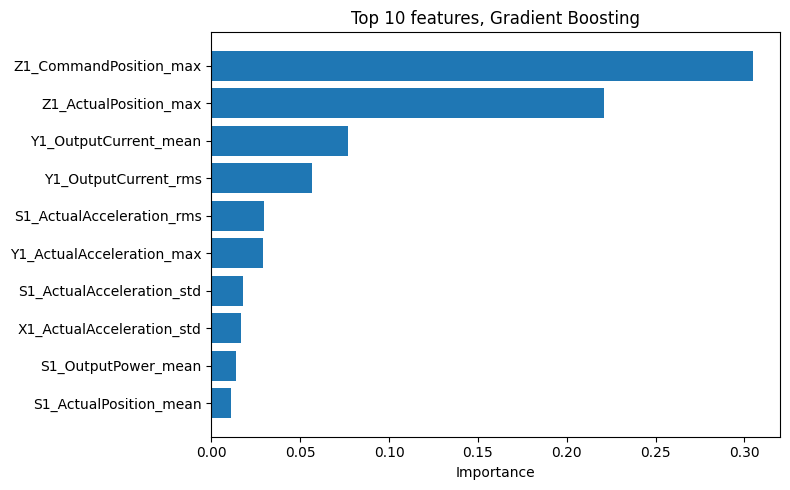

In [35]:
import matplotlib.pyplot as plt

top = imp.sort_values("Gradient Boosting", ascending=False).head(10)
plt.figure(figsize=(8, 5))
plt.barh(top["Feature"][::-1], top["Gradient Boosting"][::-1])
plt.xlabel("Importance")
plt.title("Top 10 features, Gradient Boosting")
plt.tight_layout()
plt.show()

In [34]:
imp["Sensor"] = imp["Feature"].str.rsplit("_", n=1).str[0]
by_sensor = imp.groupby("Sensor")[["Decision Tree", "Gradient Boosting"]].sum()
print(by_sensor.sort_values("Gradient Boosting", ascending=False).head(10).round(3))

                       Decision Tree  Gradient Boosting
Sensor                                                 
Z1_CommandPosition             0.108              0.310
Z1_ActualPosition              0.356              0.226
Y1_OutputCurrent               0.233              0.144
S1_ActualAcceleration          0.000              0.049
Y1_ActualAcceleration          0.034              0.031
X1_OutputCurrent               0.000              0.028
X1_ActualAcceleration          0.028              0.027
S1_ActualPosition              0.000              0.021
S1_OutputPower                 0.014              0.021
Z1_ActualAcceleration          0.000              0.016


In [36]:
check = features.groupby(["experiment", "tool_condition"])[
    ["S1_CurrentFeedback_mean", "S1_CurrentFeedback_std"]
].mean().reset_index()

print(check.groupby("tool_condition")[
    ["S1_CurrentFeedback_mean", "S1_CurrentFeedback_std"]
].mean().round(3))

                S1_CurrentFeedback_mean  S1_CurrentFeedback_std
tool_condition                                                 
unworn                           21.864                   4.529
worn                             21.611                   4.589


In [38]:
print("Top 3 features, Decision Tree:")
print(imp.sort_values("Decision Tree", ascending=False).head(3)[["Feature", "Decision Tree"]].round(3).to_string(index=False))
print()
print("Top 3 features, Gradient Boosting:")
print(imp.sort_values("Gradient Boosting", ascending=False).head(3)[["Feature", "Gradient Boosting"]].round(3).to_string(index=False))
print()
print(by_sensor.sort_values("Gradient Boosting", ascending=False).head(3).round(3))

Top 3 features, Decision Tree:
               Feature  Decision Tree
 Z1_ActualPosition_max          0.356
 Y1_OutputCurrent_mean          0.164
Z1_CommandPosition_max          0.108

Top 3 features, Gradient Boosting:
               Feature  Gradient Boosting
Z1_CommandPosition_max              0.305
 Z1_ActualPosition_max              0.221
 Y1_OutputCurrent_mean              0.077

                    Decision Tree  Gradient Boosting
Sensor                                              
Z1_CommandPosition          0.108              0.310
Z1_ActualPosition           0.356              0.226
Y1_OutputCurrent            0.233              0.144


Interpretation. Both the Decision Tree and Gradient Boosting relied mainly on the Z-axis position (commanded and actual) and the Y-axis motor output current. The Y-axis current reflects the load on the feed drive, so it plausibly relates to cutting forces that change as a tool wears. The Z-axis position has no obvious physical link to wear and may reflect differences in setup between experiments, so I treat it with caution. My hypothesis that worn tools would show higher spindle current was not supported: mean spindle current was slightly lower for worn tools (21.61 vs 21.86) and its variation was nearly identical (4.59 vs 4.53). The results are limited by having only 18 experiments, 3 of them unworn, so they are suggestive and not conclusive.

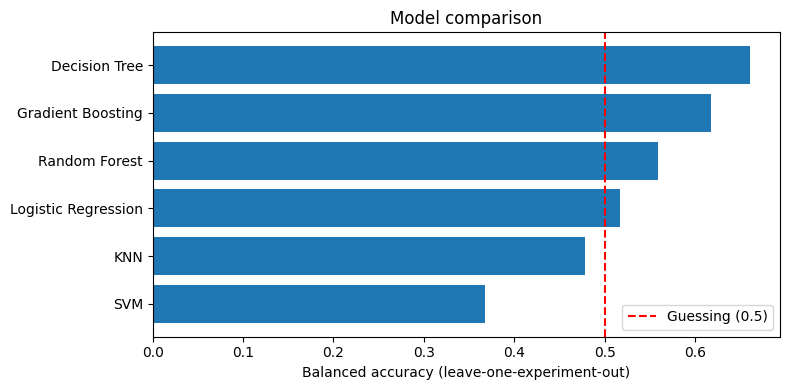

In [39]:
import matplotlib.pyplot as plt

all_feat = cv_results[cv_results["Feature set"] == "All features"].sort_values("Balanced accuracy")

plt.figure(figsize=(8, 4))
plt.barh(all_feat["Model"], all_feat["Balanced accuracy"])
plt.axvline(0.5, color="red", linestyle="--", label="Guessing (0.5)")
plt.xlabel("Balanced accuracy (leave-one-experiment-out)")
plt.title("Model comparison")
plt.legend()
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

Bars that stop short of the red dashed line are no better than guessing.

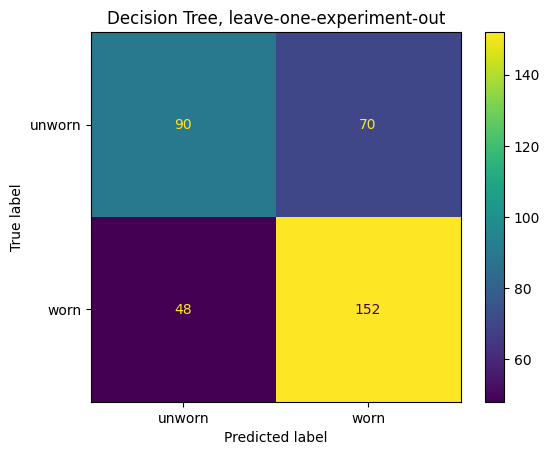

[[ 90  70]
 [ 48 152]]


In [40]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict, LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

best = make_pipeline(StandardScaler(), models["Decision Tree"])
pred = cross_val_predict(best, X_all, y_all, groups=groups, cv=LeaveOneGroupOut())

cm = confusion_matrix(y_all, pred)
ConfusionMatrixDisplay(cm, display_labels=["unworn", "worn"]).plot()
plt.title("Decision Tree, leave-one-experiment-out")
plt.savefig("confusion_matrix_best.png", dpi=150)
plt.show()
print(cm)

In [41]:
per_exp = pd.DataFrame({"experiment": groups.values, "true": y_all.values, "pred": pred})
per_exp["correct"] = per_exp["true"] == per_exp["pred"]

summary = per_exp.groupby("experiment").agg(true=("true", "first"),
                                            share_correct=("correct", "mean")).round(2)
summary["true"] = summary["true"].map({1: "worn", 0: "unworn"})
print(summary)

              true  share_correct
experiment                       
1           unworn           0.95
2           unworn           0.15
3           unworn           0.80
4           unworn           0.90
5           unworn           0.00
6             worn           0.80
7             worn           0.85
8             worn           0.95
9             worn           0.80
10            worn           0.95
11          unworn           0.60
12          unworn           0.65
13            worn           0.65
14            worn           0.90
15            worn           0.55
16            worn           0.50
17          unworn           0.45
18            worn           0.65


In [43]:
from google.colab import files

cv_results.to_csv("cv_results.csv", index=False)
files.download("cv_results.csv")
files.download("model_comparison.png")
files.download("confusion_matrix_best.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>